In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score

# Fijar semilla de reproducibilidad (2026)
SEMILLA = 2026
np.random.seed(SEMILLA)

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# Detección de la raíz del proyecto y lectura del archivo de datos
RAIZ = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'proyecto_equipo' / 'datos').is_dir() or (p / 'datos').is_dir() or (p / 'ai_company_adoption.csv').exists())

RUTA_PARQUET = list(RAIZ.glob('**/ai_company_adoption_limpio.parquet'))
if RUTA_PARQUET:
    df = pd.read_parquet(RUTA_PARQUET[0])
else:
    df = pd.read_csv(RAIZ / 'ai_company_adoption.csv')

print(f"Dataset cargado exitosamente: {df.shape[0]:,} filas | {df['company_id'].nunique():,} empresas únicas.")

Dataset cargado exitosamente: 150,000 filas | 10,000 empresas únicas.


In [2]:
# 1. Definición del Target
target_col = 'ai_adoption_stage'
orden_etapas = ['none', 'pilot', 'partial', 'full']

# 2. Análisis de distribución
distribucion = df[target_col].value_counts().reindex(orden_etapas)
porcentajes = (df[target_col].value_counts(normalize=True) * 100).reindex(orden_etapas)
resumen_clases = pd.DataFrame({'Frecuencia': distribucion, 'Porcentaje (%)': porcentajes.round(2)})
print("Distribución de clases de la variable objetivo:")
display(resumen_clases)

# 3. Selección de Features y prevención estricta de fugas
# EXCLUSIÓN: 'ai_adoption_rate', 'years_using_ai', métricas de impacto contemporáneo e identificadores
cols_cat = ['country', 'industry']
cols_log = ['num_employees', 'annual_revenue_usd_millions']
cols_std = ['company_age', 'survey_year', 'num_ai_tools_used', 'ai_training_hours']

X = df[cols_cat + cols_log + cols_std].copy()
y = df[target_col].astype('category').cat.reorder_categories(orden_etapas, ordered=True)
grupos = df['company_id'].astype('string')

# 4. Partición estratificada por grupos (Hold-out 80/20 sobre empresas completas)
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
train_idx, test_idx = next(gss.split(X, y, groups=grupos))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train = grupos.iloc[train_idx]

print(f"\nConjunto de Entrenamiento: {len(X_train):,} filas ({grupos_train.nunique():,} empresas)")
print(f"Conjunto de Prueba:        {len(X_test):,} filas ({grupos.iloc[test_idx].nunique():,} empresas)")

Distribución de clases de la variable objetivo:


,Frecuencia,Porcentaje (%)
ai_adoption_stage,,
none,5198,3.47
pilot,64317,42.88
partial,78800,52.53
full,1685,1.12



Conjunto de Entrenamiento: 119,969 filas (8,000 empresas)
Conjunto de Prueba:        30,031 filas (2,000 empresas)


In [3]:
# Pipeline de preprocesamiento unificado (ajuste exclusivo en entrenamiento)
preparador_log = Pipeline([
    ('imputar', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('escalar', StandardScaler())
])

preparador_std = Pipeline([
    ('imputar', SimpleImputer(strategy='median')),
    ('escalar', StandardScaler())
])

preparador_cat = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False))
])

preprocesador = ColumnTransformer(
    transformers=[
        ('log', preparador_log, cols_log),
        ('std', preparador_std, cols_std),
        ('cat', preparador_cat, cols_cat)
    ],
    remainder='drop'
)

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# 1. Baseline: Regresión Logística Multinomial con balanceo de pesos
pipe_lr = Pipeline([
    ('prepro', preprocesador),
    ('modelo', LogisticRegression(
        max_iter=500, 
        class_weight='balanced', 
        random_state=SEMILLA
    ))
])

# 2. No Lineal: Árbol de Decisión podado
pipe_dt = Pipeline([
    ('prepro', preprocesador),
    ('modelo', DecisionTreeClassifier(
        max_depth=8, 
        min_samples_leaf=50, 
        class_weight='balanced', 
        random_state=SEMILLA
    ))
])

# 3. Probabilístico: Naive Bayes Gaussiano
pipe_nb = Pipeline([
    ('prepro', preprocesador),
    ('modelo', GaussianNB())
])

# 4. Ensamble (Actividad D.2): Random Forest con pesos balanceados
pipe_rf = Pipeline([
    ('prepro', preprocesador),
    ('modelo', RandomForestClassifier(
        n_estimators=100, 
        max_depth=10, 
        min_samples_leaf=20, 
        class_weight='balanced', 
        random_state=SEMILLA, 
        n_jobs=2  # Evita saturar la memoria virtual en Windows
    ))
])

print("Pipelines de clasificación inicializados.")

Pipelines de clasificación inicializados.


In [5]:
# Diccionario con todos los modelos
modelos_clasif = {
    'Baseline (Regresión Logística)': pipe_lr,
    'Árbol de Decisión (max_depth=8)': pipe_dt,
    'Naive Bayes (GaussianNB)': pipe_nb,
    'Ensamble (Random Forest)': pipe_rf
}

predicciones_train = {}
predicciones_test = {}

# Entrenamiento secuencial y almacenamiento de predicciones
for nombre, modelo in modelos_clasif.items():
    print(f"Entrenando {nombre}...")
    modelo.fit(X_train, y_train)
    predicciones_train[nombre] = modelo.predict(X_train)
    predicciones_test[nombre] = modelo.predict(X_test)
    print(f" -> {nombre} ajustado y evaluado.")

print("\nFase 2 completada: Todos los modelos entrenaron exitosamente.")

Entrenando Baseline (Regresión Logística)...
 -> Baseline (Regresión Logística) ajustado y evaluado.
Entrenando Árbol de Decisión (max_depth=8)...
 -> Árbol de Decisión (max_depth=8) ajustado y evaluado.
Entrenando Naive Bayes (GaussianNB)...
 -> Naive Bayes (GaussianNB) ajustado y evaluado.
Entrenando Ensamble (Random Forest)...
 -> Ensamble (Random Forest) ajustado y evaluado.

Fase 2 completada: Todos los modelos entrenaron exitosamente.


In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

filas_metricas = []

for nombre in modelos_clasif.keys():
    y_pred_tr = predicciones_train[nombre]
    y_pred_te = predicciones_test[nombre]
    
    # Métricas en entrenamiento
    acc_tr = accuracy_score(y_train, y_pred_tr)
    f1_macro_tr = f1_score(y_train, y_pred_tr, average='macro', zero_division=0)
    
    # Métricas en prueba (evaluación honesta sobre empresas no vistas)
    acc_te = accuracy_score(y_test, y_pred_te)
    prec_macro_te = precision_score(y_test, y_pred_te, average='macro', zero_division=0)
    rec_macro_te = recall_score(y_test, y_pred_te, average='macro', zero_division=0)
    f1_macro_te = f1_score(y_test, y_pred_te, average='macro', zero_division=0)
    f1_weight_te = f1_score(y_test, y_pred_te, average='weighted', zero_division=0)
    
    filas_metricas.append({
        'Modelo': nombre,
        'Accuracy (Train)': round(acc_tr, 3),
        'Accuracy (Test)': round(acc_te, 3),
        'F1-Macro (Train)': round(f1_macro_tr, 3),
        'Precision Macro (Test)': round(prec_macro_te, 3),
        'Recall Macro (Test)': round(rec_macro_te, 3),
        'F1-Macro (Test)': round(f1_macro_te, 3),
        'F1-Weighted (Test)': round(f1_weight_te, 3),
        'Δ F1-Macro (Overfit)': round(f1_macro_tr - f1_macro_te, 3)
    })

df_comparativa_tp3 = pd.DataFrame(filas_metricas)
display(df_comparativa_tp3)

# Guardar la tabla para el informe técnico
os.makedirs("salidas_tp3", exist_ok=True)
df_comparativa_tp3.to_csv("salidas_tp3/tabla_comparativa_clasificacion_tp3.csv", index=False)
print("Tabla comparativa exportada a salidas_tp3/tabla_comparativa_clasificacion_tp3.csv")

,Modelo,Accuracy (Train),Accuracy (Test),F1-Macro (Train),Precision Macro (Test),Recall Macro (Test),F1-Macro (Test),F1-Weighted (Test),Δ F1-Macro (Overfit)
0,Baseline (Regresión Logística),0.627,0.630,0.489,0.468,0.755,0.494,0.658,-0.005
1,Árbol de Decisión (max_depth=8),0.616,0.616,0.484,0.463,0.753,0.485,0.646,-0.001
2,Naive Bayes (GaussianNB),0.536,0.535,0.405,0.393,0.621,0.408,0.559,-0.003
3,Ensamble (Random Forest),0.613,0.607,0.477,0.455,0.753,0.474,0.639,0.003


Tabla comparativa exportada a salidas_tp3/tabla_comparativa_clasificacion_tp3.csv


In [7]:
for nombre in modelos_clasif.keys():
    print("=" * 65)
    print(f"REPORTE DETALLADO (TEST): {nombre}")
    print("=" * 65)
    print(classification_report(
        y_test, 
        predicciones_test[nombre], 
        target_names=orden_etapas, 
        zero_division=0
    ))

REPORTE DETALLADO (TEST): Baseline (Regresión Logística)
              precision    recall  f1-score   support

        none       0.11      0.86      0.20       347
       pilot       0.28      0.94      0.44      1114
     partial       0.78      0.63      0.70     15661
        full       0.70      0.60      0.64     12909

    accuracy                           0.63     30031
   macro avg       0.47      0.76      0.49     30031
weighted avg       0.72      0.63      0.66     30031

REPORTE DETALLADO (TEST): Árbol de Decisión (max_depth=8)
              precision    recall  f1-score   support

        none       0.11      0.88      0.19       347
       pilot       0.28      0.93      0.43      1114
     partial       0.79      0.58      0.67     15661
        full       0.67      0.62      0.65     12909

    accuracy                           0.62     30031
   macro avg       0.46      0.75      0.48     30031
weighted avg       0.71      0.62      0.65     30031

REPORTE DETALLA

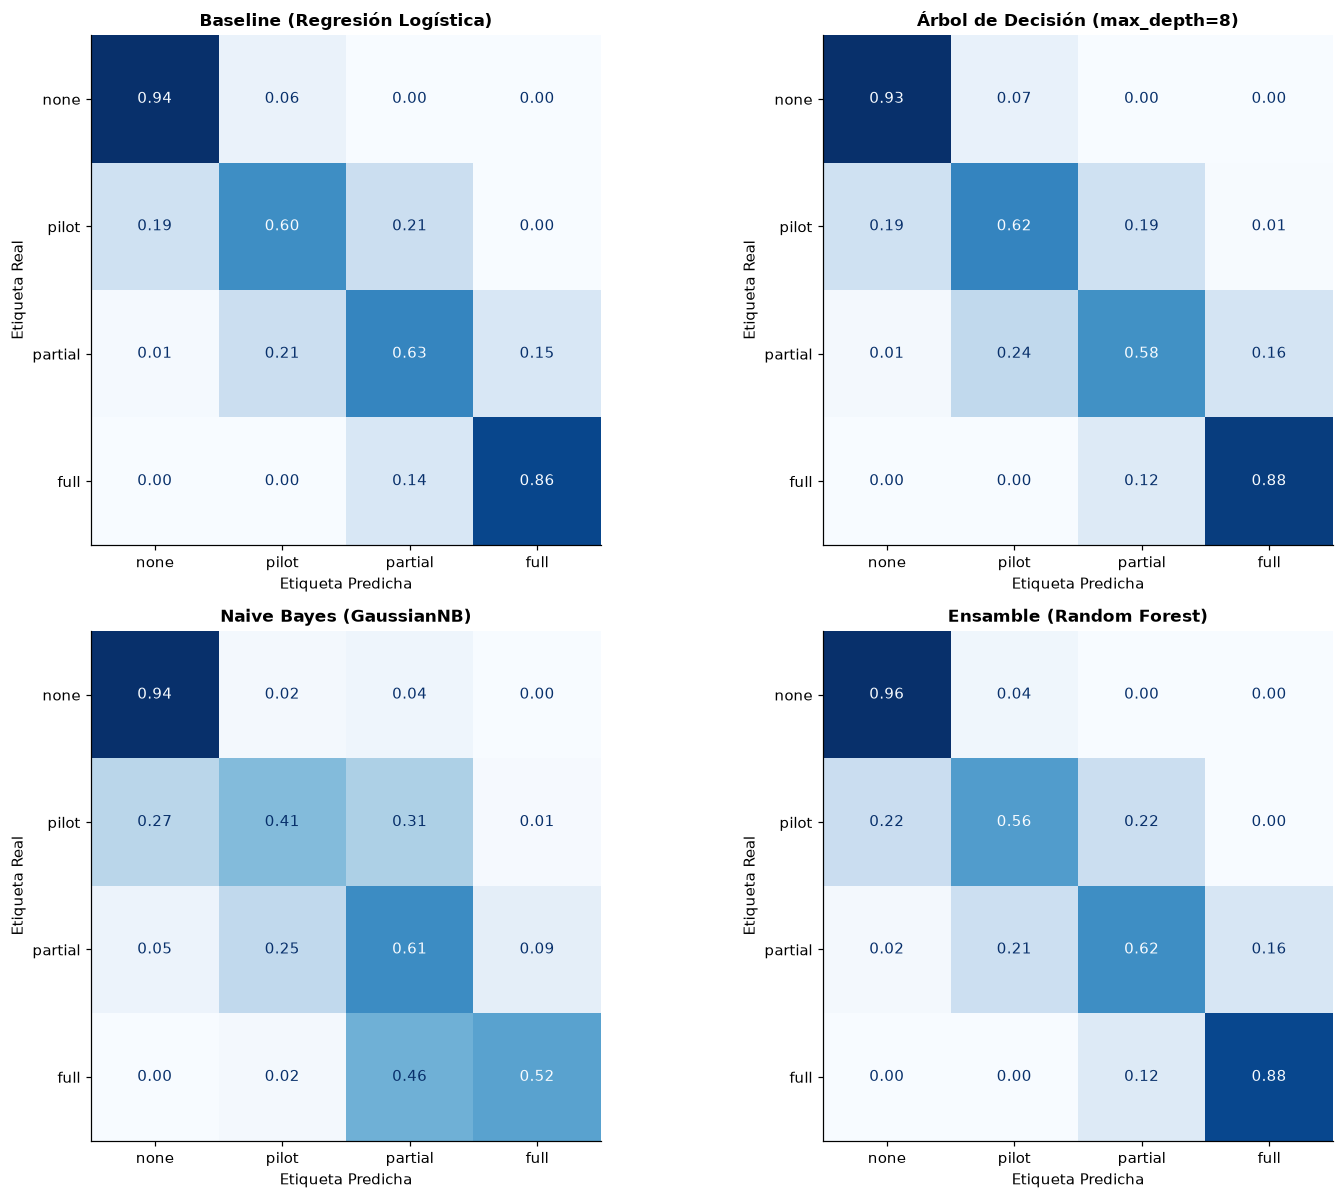

Matrices de confusión guardadas en salidas_tp3/matrices_confusion_comparadas.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for idx, (nombre, y_pred_te) in enumerate(predicciones_test.items()):
    # Matriz normalizada por filas (Recall por clase)
    cm = confusion_matrix(y_test, y_pred_te, labels=orden_etapas, normalize='true')
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=orden_etapas)
    disp.plot(
        ax=axes[idx], 
        cmap='Blues', 
        values_format='.2f', 
        colorbar=False
    )
    axes[idx].set_title(f"{nombre}", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Etiqueta Predicha")
    axes[idx].set_ylabel("Etiqueta Real")

plt.tight_layout()
plt.savefig("salidas_tp3/matrices_confusion_comparadas.png", dpi=300, bbox_inches='tight')
plt.show()
print("Matrices de confusión guardadas en salidas_tp3/matrices_confusion_comparadas.png")

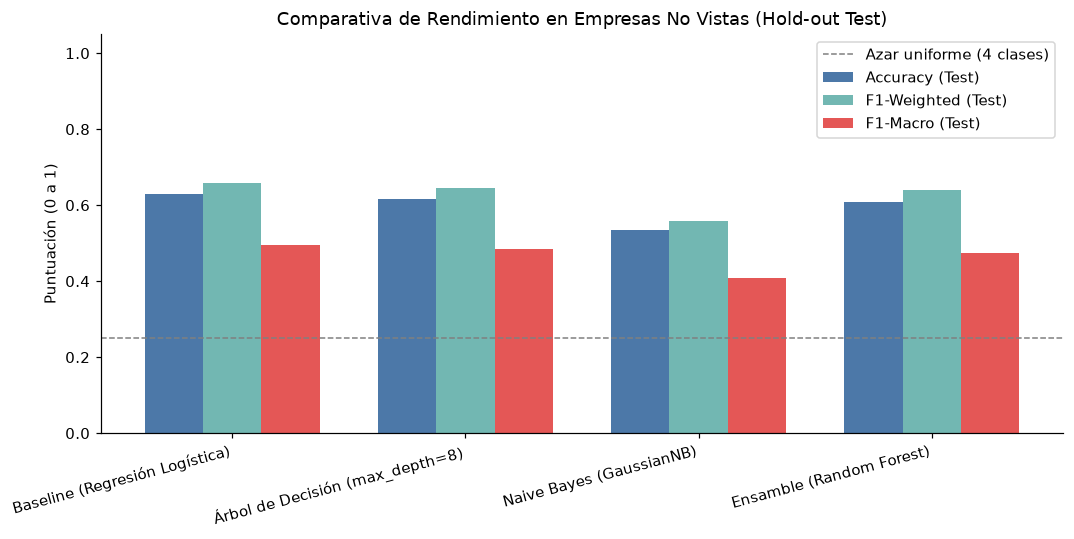

Gráfico comparativo guardado en salidas_tp3/grafico_comparativo_metricas.png


In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(df_comparativa_tp3))
ancho = 0.25

rects1 = ax.bar(x - ancho, df_comparativa_tp3['Accuracy (Test)'], ancho, label='Accuracy (Test)', color='#4C78A8')
rects2 = ax.bar(x, df_comparativa_tp3['F1-Weighted (Test)'], ancho, label='F1-Weighted (Test)', color='#72B7B2')
rects3 = ax.bar(x + ancho, df_comparativa_tp3['F1-Macro (Test)'], ancho, label='F1-Macro (Test)', color='#E45756')

ax.set_ylabel('Puntuación (0 a 1)')
ax.set_title('Comparativa de Rendimiento en Empresas No Vistas (Hold-out Test)')
ax.set_xticks(x)
ax.set_xticklabels(df_comparativa_tp3['Modelo'], rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.axhline(0.25, color='gray', linestyle='--', linewidth=1, label='Azar uniforme (4 clases)')
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig("salidas_tp3/grafico_comparativo_metricas.png", dpi=300, bbox_inches='tight')
plt.show()
print("Gráfico comparativo guardado en salidas_tp3/grafico_comparativo_metricas.png")

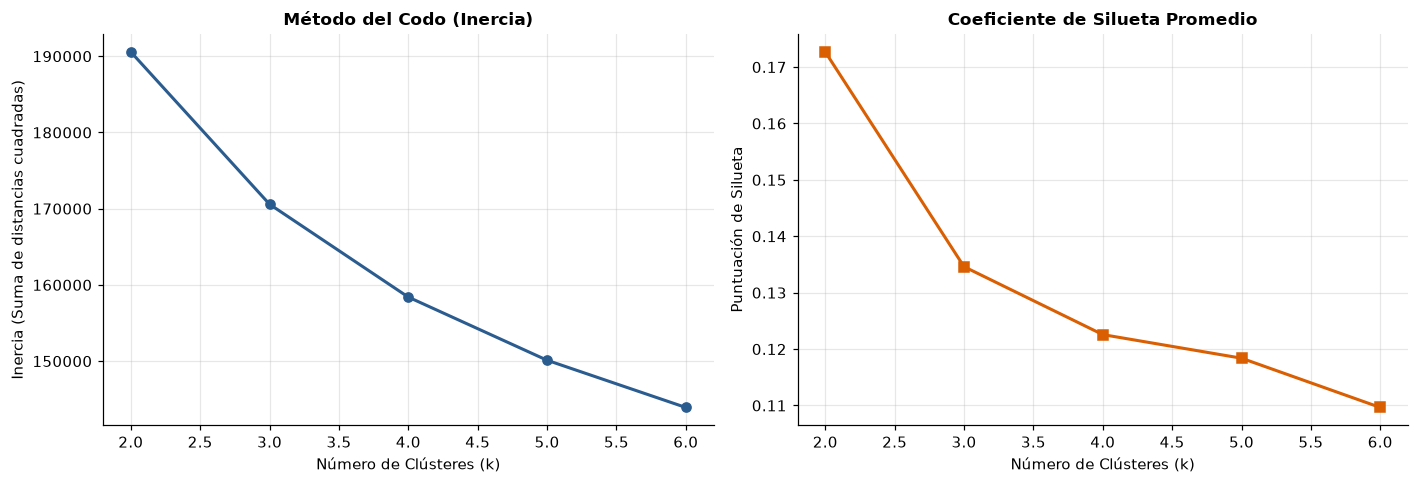

Diagnóstico de clustering guardado en salidas_tp3/diagnostico_k_optimo_clustering.png


In [10]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Transformar las features con el ColumnTransformer ya ajustado
X_train_trans = preprocesador.transform(X_train)
X_test_trans = preprocesador.transform(X_test)

# 2. Muestreo estratificado de test (para calcular silueta de forma rápida y sin saturar memoria)
np.random.seed(SEMILLA)
idx_muestra = np.random.choice(X_test_trans.shape[0], size=5000, replace=False)
X_sub = X_test_trans[idx_muestra]

inercias = []
siluetas = []
rango_k = range(2, 7)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10)
    etiquetas_k = km.fit_predict(X_test_trans)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_sub, etiquetas_k[idx_muestra]))

# 3. Gráficos de diagnóstico: Método del Codo y Coeficiente de Silueta
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(list(rango_k), inercias, marker='o', color='#2b5c8f', linewidth=2)
ax1.set_title("Método del Codo (Inercia)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Número de Clústeres (k)")
ax1.set_ylabel("Inercia (Suma de distancias cuadradas)")
ax1.grid(alpha=0.3)

ax2.plot(list(rango_k), siluetas, marker='s', color='#d95f02', linewidth=2)
ax2.set_title("Coeficiente de Silueta Promedio", fontsize=11, fontweight='bold')
ax2.set_xlabel("Número de Clústeres (k)")
ax2.set_ylabel("Puntuación de Silueta")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("salidas_tp3/diagnostico_k_optimo_clustering.png", dpi=300, bbox_inches='tight')
plt.show()

print("Diagnóstico de clustering guardado en salidas_tp3/diagnostico_k_optimo_clustering.png")

In [11]:
# Fijamos k=4 para contrastar la estructura natural contra las 4 etapas del problema
kmeans_final = KMeans(n_clusters=4, random_state=SEMILLA, n_init=10)
clusters_test = kmeans_final.fit_predict(X_test_trans)

# Mapeo a DataFrame para cruzar con las etiquetas verdaderas
df_cruce = pd.DataFrame({
    'Etapa_Real': y_test.values,
    'Cluster_KMeans': [f"Cluster {c}" for c in clusters_test]
})

# Matriz de contingencia (porcentajes por fila / Recall de coincidencia)
tabla_contingencia = pd.crosstab(
    df_cruce['Etapa_Real'], 
    df_cruce['Cluster_KMeans'], 
    normalize='index'
).reindex(orden_etapas) * 100

print("=" * 65)
print("MATRIZ DE CONTINGENCIA: ETAPAS REALES VS. CLÚSTERES K-MEANS (%)")
print("=" * 65)
display(tabla_contingencia.round(2))

# Guardar la tabla para el informe técnico
tabla_contingencia.to_csv("salidas_tp3/tabla_contingencia_clustering_tp3.csv")

MATRIZ DE CONTINGENCIA: ETAPAS REALES VS. CLÚSTERES K-MEANS (%)


Cluster_KMeans,Cluster 0,Cluster 1,Cluster 2,Cluster 3
Etapa_Real,,,,
none,0.00,2.60,52.15,45.24
pilot,10.62,11.59,39.19,38.60
partial,41.42,25.95,14.14,18.49
full,48.99,50.43,0.29,0.29


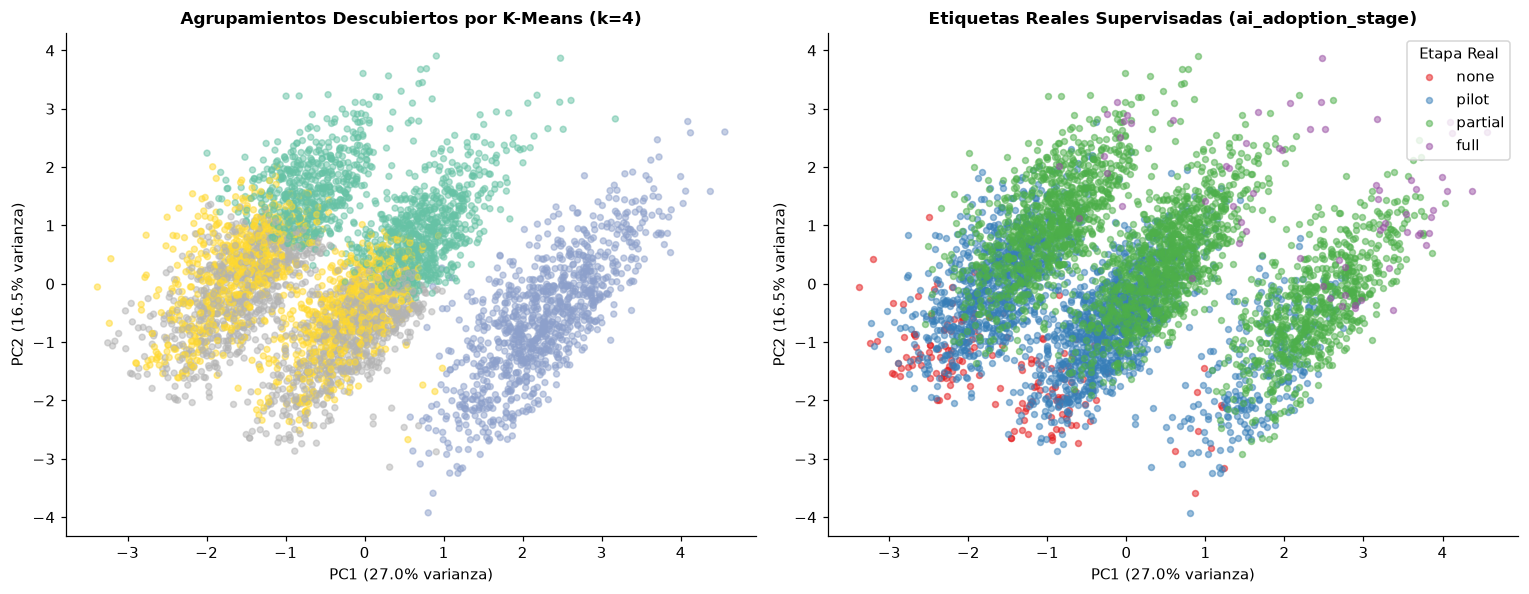

Visualización PCA guardada en salidas_tp3/dispersion_pca_clusters_vs_real.png


In [12]:
# Reducción a 2 componentes principales sobre la muestra
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X_sub)
y_sub_real = y_test.iloc[idx_muestra].values
clusters_sub = clusters_test[idx_muestra]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Proyección coloreada por Clúster K-Means
scatter1 = ax1.scatter(
    X_pca[:, 0], X_pca[:, 1], 
    c=clusters_sub, cmap='Set2', alpha=0.5, s=15
)
ax1.set_title("Agrupamientos Descubiertos por K-Means (k=4)", fontsize=11, fontweight='bold')
ax1.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)")
ax1.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)")

# 2. Proyección coloreada por Etapa de Adopción Real
paleta_etapas = {'none': '#e41a1c', 'pilot': '#377eb8', 'partial': '#4daf4a', 'full': '#984ea3'}
for etapa in orden_etapas:
    mascara = (y_sub_real == etapa)
    ax2.scatter(
        X_pca[mascara, 0], X_pca[mascara, 1], 
        label=etapa, alpha=0.5, s=15, color=paleta_etapas[etapa]
    )
ax2.set_title("Etiquetas Reales Supervisadas (ai_adoption_stage)", fontsize=11, fontweight='bold')
ax2.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)")
ax2.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)")
ax2.legend(title="Etapa Real", loc='upper right')

plt.tight_layout()
plt.savefig("salidas_tp3/dispersion_pca_clusters_vs_real.png", dpi=300, bbox_inches='tight')
plt.show()

print("Visualización PCA guardada en salidas_tp3/dispersion_pca_clusters_vs_real.png")